# PyIsing Tutorial: NP-Hard Problems as Ising Hamiltonians

This notebook demonstrates how to use the PyIsing library to convert NP-hard optimization problems into Ising spin glass Hamiltonians suitable for adiabatic quantum computation.

These formulations follow the paper by Andrew Lucas: "Ising formulations of many NP problems" (arXiv:1302.5843).

In [1]:
import sys
sys.path.insert(0, '..')

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from spinglass import SpinGlass
from simulation import Simulation

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = [8, 6]
plt.rcParams['font.size'] = 12

def display_results(sg, results, num_top=5, title=None):
    final_state = results['simulation_data'][-1]
    final_state = final_state / np.linalg.norm(final_state)
    probabilities = np.abs(final_state) ** 2

    H_matrix = sg.hamiltonian.to_matrix()
    diag = np.real(np.diag(H_matrix))

    ground_idx = np.argmin(diag)
    ground_energy = diag[ground_idx]
    ground_bitstring = format(ground_idx, f'0{sg.num_qubits}b')[::-1]
    ground_prob = probabilities[ground_idx]

    top_indices = np.argsort(probabilities)[::-1][:num_top]

    print(f"Ground state: |{ground_bitstring}>")
    print(f"Ground state energy: {ground_energy:.4f}")
    print(f"Ground state probability: {ground_prob:.4f}")
    print(f"Minimum spectral gap: {min(results['spectral_gaps']):.4f}")

    for idx in top_indices:
        bitstring = format(idx, f'0{sg.num_qubits}b')[::-1]
        energy = diag[idx]

    gaps = results['spectral_gaps']
    s_values = np.linspace(0, 1, len(gaps))
    plt.figure(figsize=(8, 4))
    plt.plot(s_values, gaps, 'b-', linewidth=2)
    min_gap = min(gaps)
    min_gap_idx = np.argmin(gaps)
    plt.axhline(y=min_gap, color='r', linestyle='--', alpha=0.5,
                label=f"Min gap = {min_gap:.4f}")
    plt.scatter([s_values[min_gap_idx]], [min_gap], color='red', s=80, zorder=5)
    plt.xlabel('Annealing parameter s=t/T')
    plt.ylabel('Spectral gap')
    plot_title = f'Spectral gap - {title}'
    plt.title(plot_title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return {
        'ground_idx': ground_idx,
        'ground_bitstring': ground_bitstring,
        'ground_energy': ground_energy,
        'ground_prob': ground_prob,
        'probabilities': probabilities,
        'diag': diag
    }

/home/pgclark/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Partitioning Problems

### Number Partitioning

Given a set of integers $S = \{s_1, s_2, ..., s_n\}$, partition them into two subsets with equal sums.

Hamiltonian: $H = \left(\sum_i s_i z_i\right)^2 = \sum_i s_i^2 + 2\sum_{i<j} s_i s_j z_i z_j$

Set to partition: [1, 2, 3, 4, 5, 6, 7, 8]
Total sum: 36
Number of qubits: 8
Hamiltonian terms: 28
Ground state: |01110000>
Ground state energy: -204.0000
Ground state probability: 0.0000
Minimum spectral gap: 0.0000


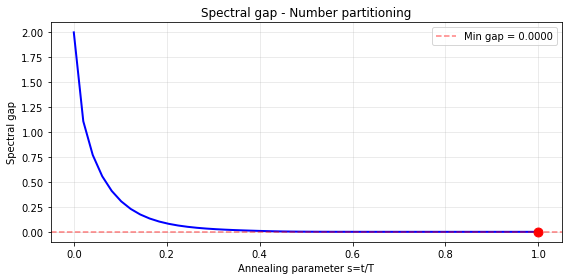

Solution (ground state |01110000>):
 Subset A: [2, 3, 4] (sum = 9)
 Subset B: [1, 5, 6, 7, 8] (sum = 27)
 Difference: 18
Valid partition (equal sums): False


In [2]:
S = [1, 2, 3, 4, 5, 6, 7, 8]
print(f"Set to partition: {S}")
print(f"Total sum: {sum(S)}")

sg = SpinGlass()
sg.fromSet(S, 'partition')

print(f"Number of qubits: {sg.num_qubits}")
print(f"Hamiltonian terms: {len(sg.hamiltonian)}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Number partitioning')

bs = res['ground_bitstring']
A = [S[i] for i in range(len(S)) if bs[i] == '1']
B = [S[i] for i in range(len(S)) if bs[i] == '0']
print(f"Solution (ground state |{bs}>):")
print(f" Subset A: {A} (sum = {sum(A)})")
print(f" Subset B: {B} (sum = {sum(B)})")
print(f" Difference: {abs(sum(A) - sum(B))}")

valid = (sum(A) == sum(B))
print(f"Valid partition (equal sums): {valid}")

### Graph Partitioning

Partition the vertices of a graph into two equal-sized sets while minimizing the number of edges between them.

**Hamiltonian:** $H = A\left(\sum_i x_i - \frac{n}{2}\right)^2 + B\sum_{(u,v)\in E} x_u(1-x_v) + (1-x_u)x_v$

Petersen graph: 10 nodes, 15 edges
Number of qubits: 10
Ground state: |0001110100>
Ground state energy: -7.2500
Ground state probability: 0.0054
Minimum spectral gap: 0.0000


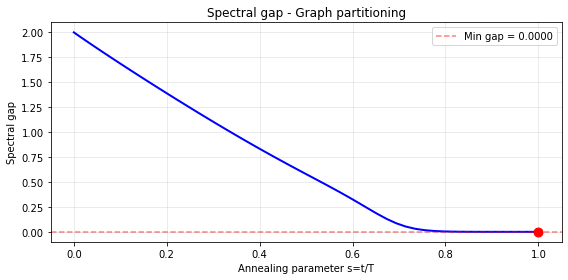

Solution (ground state |0001110100>):
Partition A: [3, 4, 5, 7]
Partition B: [0, 1, 2, 6, 8, 9]
Cut edges: 8


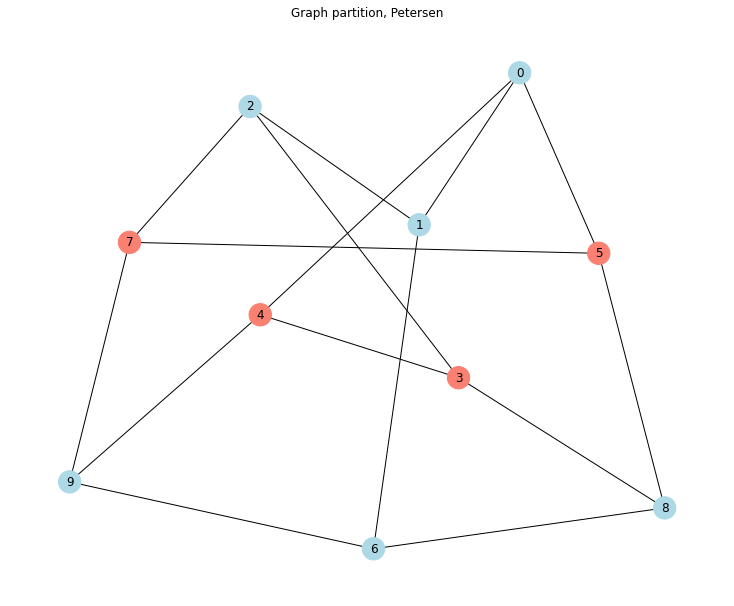

Equal partition sizes: False


In [3]:
G = nx.petersen_graph()
print(f"Petersen graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(G, 'partition')
print(f"Number of qubits: {sg.num_qubits}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Graph partitioning')

bs = res['ground_bitstring']
nodes = list(G.nodes())
part_A = [nodes[i] for i in range(len(nodes)) if bs[i] == '1']
part_B = [nodes[i] for i in range(len(nodes)) if bs[i] == '0']
cut_edges = [(u, v) for u, v in G.edges() if (u in part_A) != (v in part_A)]
print(f"Solution (ground state |{bs}>):")
print(f"Partition A: {part_A}")
print(f"Partition B: {part_B}")
print(f"Cut edges: {len(cut_edges)}")

plt.figure(figsize=(10, 8))
colors = ['salmon' if bs[i] == '1' else 'lightblue' for i in range(len(nodes))]
nx.draw(G, with_labels=True, node_color=colors, node_size=500)
plt.title("Graph partition, Petersen")
plt.show()

equal_size = (len(part_A) == len(part_B))
print(f"Equal partition sizes: {equal_size}")

### Maximum Clique

Find the largest complete subgraph (clique) in a graph.

Hamiltonian: $H = -A\sum_v x_v + B\sum_{(u,v)\notin E} x_u x_v$

Petersen graph: 10 nodes, 15 edges
Number of qubits: 10
Hamiltonian terms: 40
Ground state: |1111100000>
Ground state energy: -10.0000
Ground state probability: 0.0071
Minimum spectral gap: 0.0000


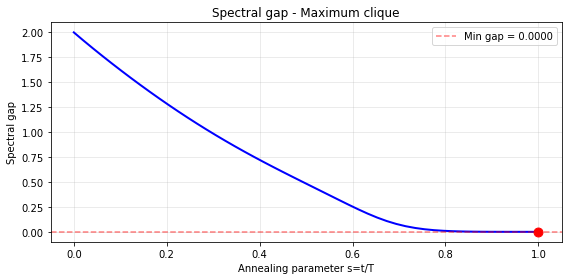

Solution (ground state |1111100000>):
Clique vertices: [0, 1, 2, 3, 4]
Clique size: 5


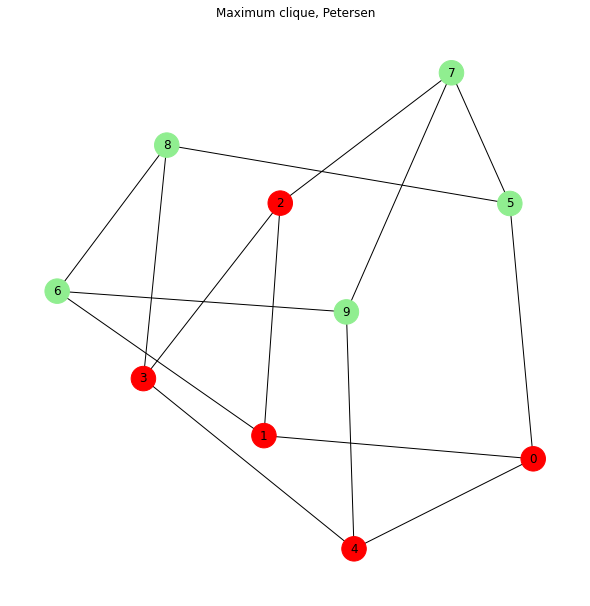

Valid clique: False


In [4]:
G = nx.petersen_graph()
print(f"Petersen graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(G, 'clique')
print(f"Number of qubits: {sg.num_qubits}")
print(f"Hamiltonian terms: {len(sg.hamiltonian)}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Maximum clique')

bs = res['ground_bitstring']
nodes = list(G.nodes())
clique_vertices = [nodes[i] for i in range(len(nodes)) if bs[i] == '1']
print(f"Solution (ground state |{bs}>):")
print(f"Clique vertices: {clique_vertices}")
print(f"Clique size: {len(clique_vertices)}")

plt.figure(figsize=(8, 8))
colors = ['red' if bs[i] == '1' else 'lightgreen' for i in range(len(nodes))]
nx.draw(G, with_labels=True, node_color=colors, node_size=600)
plt.title("Maximum clique, Petersen")
plt.show()

is_clique = all(G.has_edge(u, v) for i, u in enumerate(clique_vertices) for v in clique_vertices[i+1:])
print(f"Valid clique: {is_clique}")

## Covering and Packing Problems

### Exact Cover

Given a universe $U$ and subsets $V_1, ..., V_m$, find a collection of subsets that partition $U$.

Hamiltonian: $H = A\sum_{\alpha \in U}\left(1 - \sum_{i: \alpha \in V_i} x_i\right)^2$

Universe: [1, 2, 3, 4, 5, 6, 7]
Subsets:
V0: [1, 4, 7]
V1: [1, 4]
V2: [4, 5, 7]
V3: [3, 5, 6]
V4: [2, 3, 6, 7]
V5: [2, 7]
Number of qubits: 6
Ground state: |111110>
Ground state energy: -5.0000
Ground state probability: 0.0354
Minimum spectral gap: 0.0000


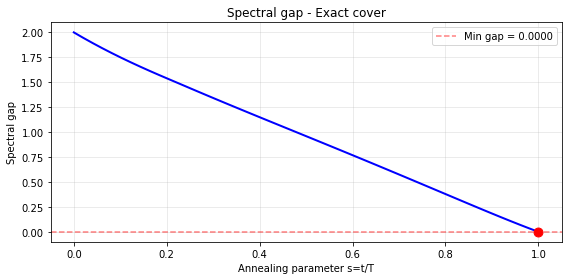

Solution (ground state |111110>):
Selected subsets: ['V0', 'V1', 'V2', 'V3', 'V4']
V0 = [1, 4, 7]
V1 = [1, 4]
V2 = [4, 5, 7]
V3 = [3, 5, 6]
V4 = [2, 3, 6, 7]
Elements covered: [1, 2, 3, 4, 5, 6, 7]
All elements covered: True
No overlapping subsets: False
Valid exact cover: False


In [5]:
exact_cover_instance = {
    'universe': [1, 2, 3, 4, 5, 6, 7],
    'subsets': [
        [1, 4, 7],
        [1, 4],
        [4, 5, 7],
        [3, 5, 6],
        [2, 3, 6, 7],
        [2, 7]
    ]
}

print(f"Universe: {exact_cover_instance['universe']}")
print(f"Subsets:")
for i, s in enumerate(exact_cover_instance['subsets']):
    print(f"V{i}: {s}")

sg = SpinGlass()
sg.fromSet(exact_cover_instance, 'exact_cover')
print(f"Number of qubits: {sg.num_qubits}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Exact cover')

bs = res['ground_bitstring']
subsets = exact_cover_instance['subsets']
selected = [i for i in range(len(subsets)) if bs[i] == '1']
covered = set()
for i in selected:
    covered.update(subsets[i])
print(f"Solution (ground state |{bs}>):")
print(f"Selected subsets: {['V'+str(i) for i in selected]}")
for i in selected:
    print(f"V{i} = {subsets[i]}")
print(f"Elements covered: {sorted(covered)}")

all_covered = (sorted(covered) == sorted(exact_cover_instance['universe']))
no_overlap = all(len(set(subsets[i]) & set(subsets[j])) == 0 for idx_i, i in enumerate(selected) for j in selected[idx_i+1:])
print(f"All elements covered: {all_covered}")
print(f"No overlapping subsets: {no_overlap}")
print(f"Valid exact cover: {all_covered and no_overlap}")

### Set Packing

Find the maximum number of pairwise disjoint subsets from a collection.

Hamiltonian: $H = -B\sum_i x_i + A\sum_{\alpha}\sum_{i<j: \alpha \in V_i \cap V_j} x_i x_j$

Universe: [1, 2, 3, 4, 5]
Subsets:
V0: [1, 2]
V1: [2, 3]
V2: [3, 4]
V3: [4, 5]
V4: [1, 5]
Number of qubits: 5
Hamiltonian terms: 10
Ground state: |11010>
Ground state energy: -2.0000
Ground state probability: 0.0494
Minimum spectral gap: 0.0000


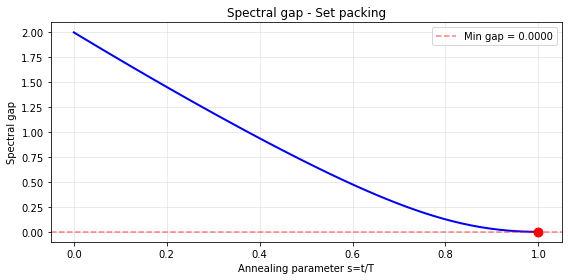

Solution (ground state |11010>):
Selected subsets: ['V0', 'V1', 'V3']
V0 = [1, 2]
V1 = [2, 3]
V3 = [4, 5]
Number of pairwise disjoint subsets: 3
Pairwise disjoint: False


In [6]:
set_packing_instance = {
    'universe': [1, 2, 3, 4, 5],
    'subsets': [
        [1, 2],
        [2, 3],
        [3, 4],
        [4, 5],
        [1, 5]
    ]
}

print(f"Universe: {set_packing_instance['universe']}")
print(f"Subsets:")
for i, s in enumerate(set_packing_instance['subsets']):
    print(f"V{i}: {s}")

sg = SpinGlass()
sg.fromSet(set_packing_instance, 'set_packing')
print(f"Number of qubits: {sg.num_qubits}")
print(f"Hamiltonian terms: {len(sg.hamiltonian)}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Set packing')

bs = res['ground_bitstring']
subsets = set_packing_instance['subsets']
selected = [i for i in range(len(subsets)) if bs[i] == '1']
print(f"Solution (ground state |{bs}>):")
print(f"Selected subsets: {['V'+str(i) for i in selected]}")
for i in selected:
    print(f"V{i} = {subsets[i]}")
print(f"Number of pairwise disjoint subsets: {len(selected)}")

pairwise_disjoint = all(len(set(subsets[i]) & set(subsets[j])) == 0 for idx_i, i in enumerate(selected) for j in selected[idx_i+1:])
print(f"Pairwise disjoint: {pairwise_disjoint}")

### Vertex Cover

Find the minimum set of vertices such that every edge has at least one endpoint in the set.

Hamiltonian: $H = B\sum_v x_v + A\sum_{(u,v)\in E}(1-x_u)(1-x_v)$

House graph: 5 nodes, 6 edges
Number of qubits: 5
Ground state: |10110>
Ground state energy: -2.5000
Ground state probability: 0.0549
Minimum spectral gap: 0.0000


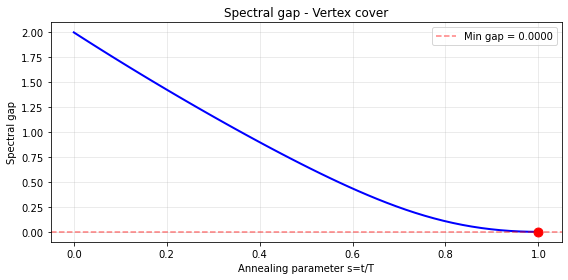

Solution (ground state |10110>):
Vertex cover: [0, 2, 3]
Cover size: 3


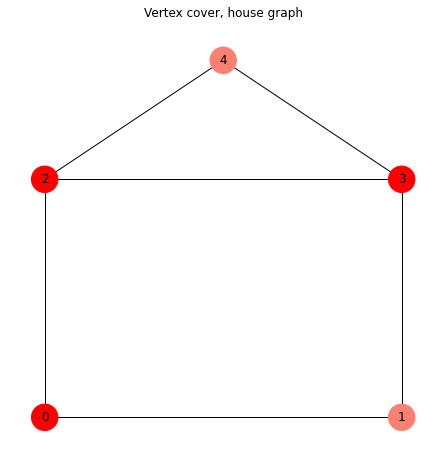

All edges covered: True


In [7]:
G = nx.house_graph()
print(f"House graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(G, 'covering')
print(f"Number of qubits: {sg.num_qubits}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Vertex cover')

bs = res['ground_bitstring']
nodes = list(G.nodes())
cover = [nodes[i] for i in range(len(nodes)) if bs[i] == '1']
print(f"Solution (ground state |{bs}>):")
print(f"Vertex cover: {cover}")
print(f"Cover size: {len(cover)}")

plt.figure(figsize=(6, 6))
pos = {0: (0, 0), 1: (1, 0), 2: (0, 1), 3: (1, 1), 4: (0.5, 1.5)}
colors = ['red' if bs[i] == '1' else 'salmon' for i in range(len(nodes))]
nx.draw(G, pos, with_labels=True, node_color=colors, node_size=700)
plt.title("Vertex cover, house graph")
plt.show()

all_edges_covered = all(u in cover or v in cover for u, v in G.edges())
print(f"All edges covered: {all_edges_covered}")

### Boolean Satisfiability (3-SAT)

Find a truth assignment satisfying a Boolean formula in conjunctive normal form (CNF).

Hamiltonian: $H_C = A(1-l_1)(1-l_2)(1-l_3)$

Number of variables: 4
Number of clauses: 4
Clauses:
Clause 1: (x0 OR x1 OR NOT x2)
Clause 2: (NOT x0 OR x2 OR x3)
Clause 3: (x1 OR x2 OR NOT x3)
Clause 4: (x0 OR NOT x1 OR x3)
Number of qubits: 8 (4 variables + 4 ancillas)
Ground state: |01010000>
Ground state energy: -10.0000
Ground state probability: 0.0256
Minimum spectral gap: 0.0000


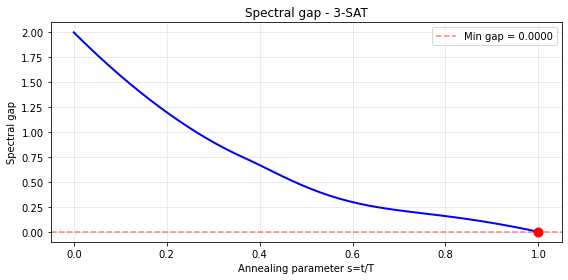

Solution (ground state |01010000>):
Variable assignments: {'x0': False, 'x1': True, 'x2': False, 'x3': True}
Clause 1 (x0 OR x1 OR NOT x2): SAT
Clause 2 (NOT x0 OR x2 OR x3): SAT
Clause 3 (x1 OR x2 OR NOT x3): SAT
Clause 4 (x0 OR NOT x1 OR x3): SAT
All clauses satisfied: True


In [8]:
sat_instance = {
    'num_variables': 4,
    'clauses': [
        [(0, False), (1, False), (2, True)],
        [(0, True), (2, False), (3, False)],
        [(1, False), (2, False), (3, True)],
        [(0, False), (1, True), (3, False)]
    ]
}

n_vars = sat_instance['num_variables']
n_clauses = len(sat_instance['clauses'])
n_3_clauses = sum(1 for c in sat_instance['clauses'] if len(c) == 3)

print(f"Number of variables: {n_vars}")
print(f"Number of clauses: {n_clauses}")
print("Clauses:")
for i, clause in enumerate(sat_instance['clauses']):
    clause_str = " OR ".join([f"{'NOT ' if neg else ''}x{var}" for var, neg in clause])
    print(f"Clause {i+1}: ({clause_str})")

sg = SpinGlass()
sg.fromSet(sat_instance, 'sat')
print(f"Number of qubits: {sg.num_qubits} ({n_vars} variables + {n_3_clauses} ancillas)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='3-SAT')

bs = res['ground_bitstring']
assignment = {f'x{i}': (bs[i] == '1') for i in range(n_vars)}
print(f"Solution (ground state |{bs}>):")
print(f"Variable assignments: {assignment}")
all_sat = True
for i, clause in enumerate(sat_instance['clauses']):
    vals = []
    for var, negated in clause:
        val = (bs[var] == '1')
        vals.append((not val) if negated else val)
    satisfied = any(vals)
    all_sat = all_sat and satisfied
    clause_str = " OR ".join([f"{'NOT ' if neg else ''}x{var}" for var, neg in clause])
    print(f"Clause {i+1} ({clause_str}): {'SAT' if satisfied else 'UNSAT'}")
print(f"All clauses satisfied: {all_sat}")

### Minimal-maximal Matching

Find a matching (set of edges with no shared vertices) that is maximal (cannot add more edges) and minimal (smallest such maximal matching).

Hamiltonian: $H = -B\sum_e x_e + A\sum_v \sum_{e_1 < e_2 \in \delta(v)} x_{e_1} x_{e_2}$

C6: 6 nodes, 6 edges
Number of qubits (edges): 6
Ground state: |111111>
Ground state energy: -6.0000
Ground state probability: 0.0370
Minimum spectral gap: 0.8877


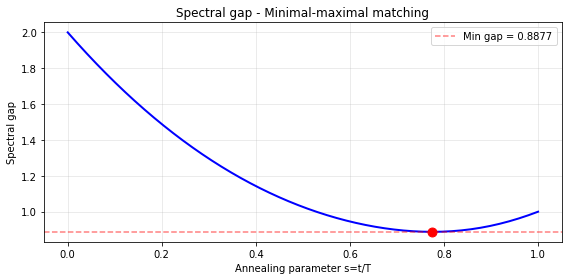

Solution (ground state |111111>):
Matching edges: [(0, 1), (0, 5), (1, 2), (2, 3), (3, 4), (4, 5)]
Matching size: 6


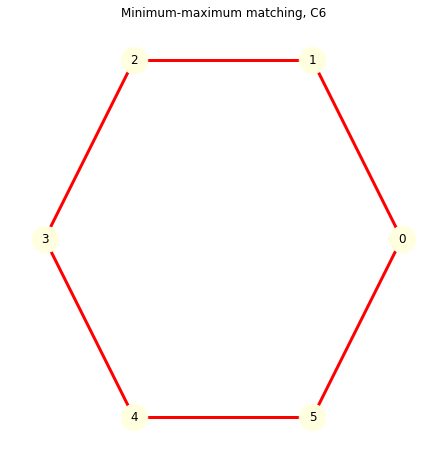

Valid matching (no shared vertices): False
Maximal matching: True


In [9]:
G = nx.cycle_graph(6)
print(f"C6: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(G, 'minimal_maximal_matching')
print(f"Number of qubits (edges): {sg.num_qubits}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Minimal-maximal matching')

bs = res['ground_bitstring']
edges = list(G.edges())
matching = [edges[i] for i in range(len(edges)) if bs[i] == '1']
print(f"Solution (ground state |{bs}>):")
print(f"Matching edges: {matching}")
print(f"Matching size: {len(matching)}")

plt.figure(figsize=(6, 6))
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels=True, node_color='lightyellow', node_size=700, width=1)
matching_edges = [edges[i] for i in range(len(edges)) if bs[i] == '1']
nx.draw_networkx_edges(G, pos, edgelist=matching_edges, edge_color='red', width=3)
plt.title("Minimum-maximum matching, C6")
plt.show()

matched_vertices = [v for e in matching for v in e]
no_shared = (len(matched_vertices) == len(set(matched_vertices)))
unmatched = set(G.nodes()) - set(matched_vertices)
is_maximal = all(any(v in set(matched_vertices) for v in e) for e in G.edges() if set(e) & unmatched)
print(f"Valid matching (no shared vertices): {no_shared}")
print(f"Maximal matching: {is_maximal}")

## Problems with Inequalities

### Set Cover

Find the minimum number of subsets that cover all elements of the universe.

Hamiltonian: $H = B\sum_i x_i + A\sum_{\alpha}\left(\sum_{i: \alpha \in V_i} x_i - y_\alpha - 1\right)^2$

Universe: [1, 2, 3, 4, 5]
Subsets:
V0: [1, 2, 3]
V1: [2, 4]
V2: [3, 4]
V3: [4, 5]
V4: [1, 5]
Number of qubits: 11 (5 subset variables + 6 slack bits)
Ground state: |11111111111>
Ground state energy: -24.0000
Ground state probability: 0.0997
Minimum spectral gap: 1.5469


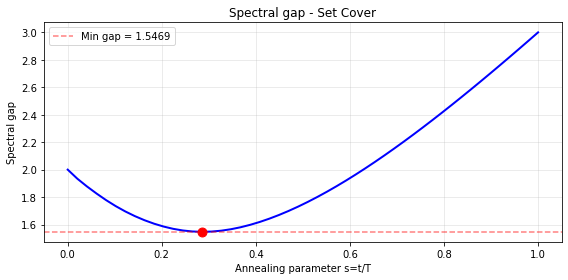

Solution (ground state |11111111111>, first 5 bits):
Selected subsets: ['V0', 'V1', 'V2', 'V3', 'V4']
V0 = [1, 2, 3]
V1 = [2, 4]
V2 = [3, 4]
V3 = [4, 5]
V4 = [1, 5]
Elements covered: [1, 2, 3, 4, 5]
Universe covered: True


In [10]:
set_cover_instance = {
    'universe': [1, 2, 3, 4, 5],
    'subsets': [
        [1, 2, 3],
        [2, 4],
        [3, 4],
        [4, 5],
        [1, 5]
    ]
}

sg = SpinGlass()
sg.fromSet(set_cover_instance, 'set_cover')

m = len(set_cover_instance['subsets'])
print(f"Universe: {set_cover_instance['universe']}")
print(f"Subsets:")
for i, s in enumerate(set_cover_instance['subsets']):
    print(f"V{i}: {s}")
print(f"Number of qubits: {sg.num_qubits} ({m} subset variables + {sg.num_qubits - m} slack bits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Set Cover')

bs = res['ground_bitstring']
subsets = set_cover_instance['subsets']
selected = [i for i in range(m) if bs[i] == '1']
covered = set()
for i in selected:
    covered.update(subsets[i])
print(f"Solution (ground state |{bs}>, first {m} bits):")
print(f"Selected subsets: {['V'+str(i) for i in selected]}")
for i in selected:
    print(f"V{i} = {subsets[i]}")
print(f"Elements covered: {sorted(covered)}")
print(f"Universe covered: {covered >= set(set_cover_instance['universe'])}")

### Knapsack Problem

Given items with weights $w_i$ and values $v_i$, and capacity $W$, maximize value subject to weight constraint.

Hamiltonian: $H = -B\sum_i v_i x_i + A\left(\sum_i w_i x_i + \sum_k 2^k y_k - W\right)^2$

Items (weight, value):
Item 0: weight=2, value=3
Item 1: weight=3, value=4
Item 2: weight=4, value=5
Item 3: weight=5, value=6
Capacity: 7
Number of qubits: 7 (4 item qubits + 3 slack qubits)
Ground state: |0000100>
Ground state energy: -232.2500
Ground state probability: 0.0000
Minimum spectral gap: 0.0444


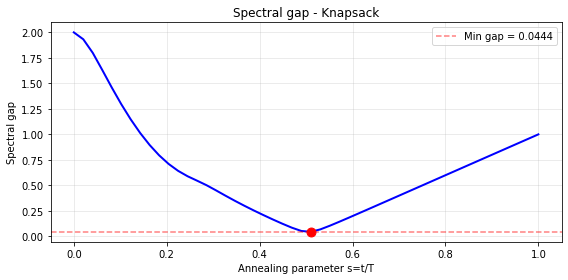

Solution (ground state |0000100>, first 4 bits):
Selected items: []
Total weight: 0 / 7
Total value: 0
Within capacity: True


In [11]:
knapsack_instance = {
    'weights': [2, 3, 4, 5],
    'values': [3, 4, 5, 6],
    'capacity': 7
}

print(f"Items (weight, value):")
for i, (w, v) in enumerate(zip(knapsack_instance['weights'], knapsack_instance['values'])):
    print(f"Item {i}: weight={w}, value={v}")
print(f"Capacity: {knapsack_instance['capacity']}")

sg = SpinGlass()
sg.fromSet(knapsack_instance, 'knapsack')

n_items = len(knapsack_instance['weights'])
print(f"Number of qubits: {sg.num_qubits} ({n_items} item qubits + {sg.num_qubits - n_items} slack qubits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Knapsack')

bs = res['ground_bitstring']
weights = knapsack_instance['weights']
values = knapsack_instance['values']
selected = [i for i in range(n_items) if bs[i] == '1']
total_weight = sum(weights[i] for i in selected)
total_value = sum(values[i] for i in selected)
print(f"Solution (ground state |{bs}>, first {n_items} bits):")
print(f"Selected items: {selected}")
for i in selected:
    print(f"Item {i}: weight={weights[i]}, value={values[i]}")
print(f"Total weight: {total_weight} / {knapsack_instance['capacity']}")
print(f"Total value: {total_value}")

within_capacity = (total_weight <= knapsack_instance['capacity'])
print(f"Within capacity: {within_capacity}")

## Coloring Problems

### Graph Coloring

Color vertices so that no two adjacent vertices have the same color, using $k$ colors.

Hamiltonian: $H_A = A\sum_v\left(1 - \sum_c x_{v,c}\right)^2$, $H_B = A\sum_{(u,v)\in E}\sum_c x_{u,c}x_{v,c}$

C4: 4 nodes, 4 edges
Chromatic number: 2
Number of qubits: 8 (4 vertices x 2 colors = 8 qubits)
Ground state: |01100110>
Ground state energy: -6.0000
Ground state probability: 0.0181
Minimum spectral gap: 0.0000


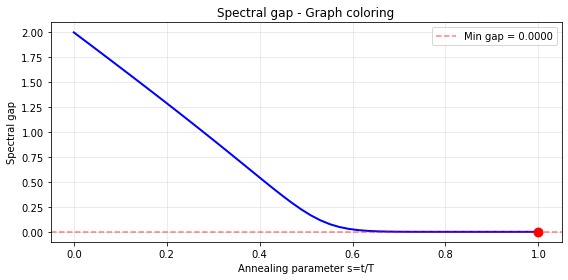

Solution (ground state |01100110>):
  Vertex 0: Blue
  Vertex 1: Red
  Vertex 2: Blue
  Vertex 3: Red
Valid coloring: True


In [12]:
G = nx.cycle_graph(4)
print(f"C4: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Chromatic number: 2")

k = 2
sg = SpinGlass()
sg.fromGraph(G, 'coloring', k=k)

n = G.number_of_nodes()
print(f"Number of qubits: {sg.num_qubits} ({n} vertices x {k} colors = {n * k} qubits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title=f'Graph coloring')

bs = res['ground_bitstring']
color_names = ['Red', 'Blue', 'Green', 'Yellow'][:k]
print(f"Solution (ground state |{bs}>):")
coloring = {}
for v in range(n):
    for c in range(k):
        if bs[v * k + c] == '1':
            coloring[v] = c
            print(f"  Vertex {v}: {color_names[c]}")
            break
valid = all(coloring.get(u) != coloring.get(v) for u, v in G.edges() if u in coloring and v in coloring)
print(f"Valid coloring: {valid}")

### Clique Cover

Partition vertices into $k$ cliques (complete subgraphs).

Hamiltonian: $H = A\sum_v\left(1 - \sum_c x_{v,c}\right)^2 + A\sum_{(u,v)\notin E}\sum_c x_{u,c}x_{v,c}$

In [13]:
G = nx.complete_bipartite_graph(3, 3)
print(f"K3,3: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

k = 3
sg = SpinGlass()
sg.fromGraph(G, 'clique_cover', k=k)

n = G.number_of_nodes()
print(f"Number of cliques: {k}")
print(f"Number of qubits: {sg.num_qubits} ({n} vertices x {k} cliques)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title=f'Clique cover')

bs = res['ground_bitstring']
print(f"\nSolution (ground state |{bs}>):")
for c in range(k):
    members = [v for v in range(n) if bs[v * k + c] == '1']
    print(f"  Clique {c}: vertices {members}")

plt.figure(figsize=(8, 6))
pos = nx.bipartite_layout(G, [0, 1, 2])
nx.draw(G, pos, with_labels=True, node_color='lightcoral', node_size=700)
plt.title("Clique cover, K3,3")
plt.show()

assigned = {}
for c in range(k):
    members = [v for v in range(n) if bs[v * k + c] == '1']
    for v in members:
        assigned[v] = c
all_assigned = (len(assigned) == n)
valid_cliques = all(G.has_edge(u, v) for c_id in range(k) for i, u in enumerate([v for v in range(n) if assigned.get(v) == c_id]) for v in [v for v in range(n) if assigned.get(v) == c_id][i+1:])
print(f"All vertices assigned: {all_assigned}")
print(f"Valid cliques: {valid_cliques}")

K3,3: 6 nodes, 9 edges
Number of cliques: 3
Number of qubits: 18 (6 vertices x 3 cliques)


MemoryError: Unable to allocate 512. GiB for an array with shape (262144, 262144) and data type float64

### Job Sequencing with Integer Lengths

Schedule jobs with processing times and deadlines to minimize weighted tardiness.

Hamiltonian: $H = A\sum_j \left(1 - \sum_t x_{j,t}\right)^2 + A\sum_t \sum_{j \neq j'} x_{j,t} x_{j',t'} + B\sum_j w_j \max(0, C_j - d_j)$

In [14]:
jobs = [2, 3, 1]
deadlines = [3, 5, 2]
weights = [1, 2, 3]

for i, (p, d, w) in enumerate(zip(jobs, deadlines, weights)):
    print(f"Job {i}: processing_time={p}, deadline={d}, weight={w}")

sg = SpinGlass()
sg.fromSchedule(jobs, deadlines, weights)

T = sum(jobs)
n = len(jobs)
print(f"Total makespan: {T}")
print(f"Number of qubits: {sg.num_qubits} ({n} jobs x {T} time slots)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Job Sequencing')

bs = res['ground_bitstring']
print(f"Solution (ground state |{bs}>):")
total_tardiness = 0
for j in range(n):
    for t in range(T):
        if bs[j * T + t] == '1':
            completion = t + jobs[j]
            tardiness = max(0, completion - deadlines[j])
            total_tardiness += weights[j] * tardiness
            print(f"Job {j}: starts at t={t}, completes at t={completion}, "
                  f"deadline={deadlines[j]}, tardiness={tardiness}")
            break
print(f"Total weighted tardiness: {total_tardiness}")

scheduled_jobs = []
for j in range(n):
    starts = [t for t in range(T) if bs[j * T + t] == '1']
    scheduled_jobs.append(len(starts))
all_once = all(s == 1 for s in scheduled_jobs)
print(f"Each job scheduled exactly once: {all_once}")

Job 0: processing_time=2, deadline=3, weight=1
Job 1: processing_time=3, deadline=5, weight=2
Job 2: processing_time=1, deadline=2, weight=3
Total makespan: 6
Number of qubits: 18 (3 jobs x 6 time slots)


MemoryError: Unable to allocate 512. GiB for an array with shape (262144, 262144) and data type float64

## Hamiltonian Cycles and Paths

### Hamiltonian Cycle

Find a cycle that visits every vertex exactly once.

Hamiltonian: $H = A\sum_v \left(1 - \sum_p x_{v,p}\right)^2 + A\sum_p \left(1 - \sum_v x_{v,p}\right)^2 + A\sum_{(u,v)\notin E}\sum_p x_{u,p} x_{v,p+1}$

In [15]:
G = nx.cycle_graph(4)
print(f"C4: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(G, 'hamiltonian')

n = G.number_of_nodes()
print(f"Number of qubits: {sg.num_qubits} ({n} vertices x {n} positions)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Hamiltonian cycle')

bs = res['ground_bitstring']
nodes = list(G.nodes())
print(f"Solution (ground state |{bs}>):")
print(f"Position matrix:")
tour = [None] * n
for v in range(n):
    row = [bs[v * n + p] for p in range(n)]
    positions = [p for p in range(n) if bs[v * n + p] == '1']
    print(f"Vertex {v}: {row}")
    for p in positions:
        tour[p] = nodes[v]
print(f"Tour: {tour}")

plt.figure(figsize=(8, 8))
nx.draw_circular(G, with_labels=True, node_color='lightblue', node_size=500)
plt.title("Hamiltonian cycle, C4")
plt.show()

valid_tour = (all(t is not None for t in tour) and len(set(tour)) == n)
valid_edges = valid_tour and all(G.has_edge(tour[i], tour[(i+1) % n]) for i in range(n))
print(f"Valid Hamiltonian cycle: {valid_edges}")

C4: 4 nodes, 4 edges
Number of qubits: 16 (4 vertices x 4 positions)


MemoryError: Unable to allocate 32.0 GiB for an array with shape (65536, 65536) and data type float64

### Traveling Salesman Problem (TSP)

Find the minimum weight Hamiltonian cycle in a weighted graph.

Hamiltonian: $H = A\sum_v \left(1 - \sum_p x_{v,p}\right)^2 + A\sum_p \left(1 - \sum_v x_{v,p}\right)^2 + B\sum_{(u,v)\in E} w_{uv}\sum_p x_{u,p} x_{v,p+1}$

In [16]:
n_cities = 5
np.random.seed(42)
positions = {i: (np.random.rand(), np.random.rand()) for i in range(n_cities)}

G = nx.complete_graph(n_cities)
for u, v in G.edges():
    dist = np.sqrt((positions[u][0] - positions[v][0])**2 + 
                   (positions[u][1] - positions[v][1])**2)
    G[u][v]['weight'] = round(dist * 100)

print(f"TSP:{n_cities} cities")
print("Edge weights (distances):")
for u, v, d in G.edges(data=True):
    print(f"{u}<->{v}:{d['weight']}")

sg = SpinGlass()
sg.fromGraph(G, 'tsp')

print(f"Number of qubits: {sg.num_qubits} ({n_cities} cities x {n_cities} positions)")

# Run simulation
sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title=f'TSP')

bs = res['ground_bitstring']
n = n_cities
nodes = list(G.nodes())
print(f"\olution (ground state |{bs}>):")
tour = [None] * n
for v in range(n):
    for p in range(n):
        if bs[v * n + p] == '1':
            tour[p] = nodes[v]
print(f"  Tour: {tour}")
if all(t is not None for t in tour):
    cost = sum(G[tour[i]][tour[(i+1) % n]]['weight'] for i in range(n))
    print(f"Tour cost: {cost}")

plt.figure(figsize=(8, 8))
nx.draw(G, positions, with_labels=True, node_color='gold', node_size=700)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, positions, edge_labels)
plt.title("TSP")
plt.show()

valid_tour_check = (all(t is not None for t in tour) and len(set(tour)) == n)
valid_edges_check = valid_tour_check and all(G.has_edge(tour[i], tour[(i+1) % n]) for i in range(n))
print(f"Valid tour: {valid_edges_check}")

TSP:5 cities
Edge weights (distances):
0<->1:50
0<->2:82
0<->3:33
0<->4:33
1<->2:73
1<->3:73
1<->4:17
2<->3:72
2<->4:71
3<->4:57
Number of qubits: 25 (5 cities x 5 positions)


MemoryError: Unable to allocate 8.00 PiB for an array with shape (33554432, 33554432) and data type float64

## Tree Problems

### Minimum Spanning Tree

Find a minimum weight spanning tree (exactly $n-1$ edges, no cycles, connected).

Hamiltonian: $H = B\sum_e w_e x_e + A\left(\sum_e x_e - (n-1)\right)^2 + A\sum_{\text{cycles } C}\left(\sum_{e\in C} x_e - |C| + y_C\right)^2$

In [17]:
G = nx.complete_graph(5)
np.random.seed(123)
for u, v in G.edges():
    G[u][v]['weight'] = np.random.randint(1, 10)

print(f"K5, random weights")
print("Edge weights:")
for u, v, d in G.edges(data=True):
    print(f"{u}<->{v}:{d['weight']}")

sg = SpinGlass()
sg.fromGraph(G, 'mst')

m = G.number_of_edges()
print(f"Number of qubits: {sg.num_qubits} ({m} edge variables + {sg.num_qubits - m} slack bits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='MST')

bs = res['ground_bitstring']
edges = list(G.edges(data=True))
selected = [(u, v, d['weight']) for i, (u, v, d) in enumerate(edges) if bs[i] == '1']
print(f"Solution (ground state |{bs}>, first {m} bits):")
print(f"Selected edges:")
total_weight = 0
for u, v, w in selected:
    print(f"{u}<->{v}: weight {w}")
    total_weight += w
print(f"Total weight: {total_weight}")
print(f"Number of edges: {len(selected)} (need {G.number_of_nodes()-1} for spanning tree)")

plt.figure(figsize=(8, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightgreen', node_size=700, width=1, alpha=0.5)
selected_edges = [(u, v) for u, v, w in selected]
nx.draw_networkx_edges(G, pos, edgelist=selected_edges, edge_color='red', width=3)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels)
plt.title("MST")
plt.show()

T_graph = nx.Graph()
T_graph.add_edges_from([(u, v) for u, v, w in selected])
is_tree = nx.is_tree(T_graph) and T_graph.number_of_nodes() == G.number_of_nodes()
print(f"Valid spanning tree: {is_tree}")

K5, random weights
Edge weights:
0<->1:3
0<->2:3
0<->3:7
0<->4:2
1<->2:4
1<->3:7
1<->4:2
2<->3:1
2<->4:2
3<->4:1
Number of qubits: 22 (10 edge variables + 12 slack bits)


MemoryError: Unable to allocate 128. TiB for an array with shape (4194304, 4194304) and data type float64

### Steiner Tree

Find the minimum weight tree connecting a subset of terminal vertices.

Hamiltonian: $H = B\sum_e w_e x_e + A\sum_{t \in T}\left(\sum_{e\in\delta(t)} x_e - 1 - y_t\right)^2 + A\sum_{\text{cycles } C}\left(\sum_{e\in C} x_e - |C| + y_C\right)^2$

In [18]:
G = nx.grid_2d_graph(3, 3)
G = nx.convert_node_labels_to_integers(G)
for u, v in G.edges():
    G[u][v]['weight'] = 1

terminals = [0, 2, 6, 8]
print(f"Grid graph")
print(f"Terminal vertices: {terminals}")

sg = SpinGlass()
sg.fromGraph(G, 'steiner_tree', terminals=terminals)

m = G.number_of_edges()
print(f"Number of qubits: {sg.num_qubits} ({m} edge variables + {sg.num_qubits - m} slack bits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Steiner tree')

bs = res['ground_bitstring']
edges = list(G.edges())
selected = [edges[i] for i in range(m) if bs[i] == '1']
print(f"Solution (ground state |{bs}>, first {m} bits):")
print(f"Selected edges: {selected}")
print(f"Number of edges: {len(selected)}")

plt.figure(figsize=(6, 6))
pos = {i: (i % 3, i // 3) for i in range(9)}
colors = ['red' if i in terminals else 'lightblue' for i in range(9)]
nx.draw(G, pos, with_labels=True, node_color=colors, node_size=500, width=1, alpha=0.5)
nx.draw_networkx_edges(G, pos, edgelist=selected, edge_color='red', width=3)
plt.title("Grid graph, Steiner tree")
plt.show()

S_graph = nx.Graph()
S_graph.add_edges_from(selected)
terminals_connected = all(nx.has_path(S_graph, terminals[0], t) for t in terminals[1:]) if len(selected) > 0 else False
print(f"All terminals connected: {terminals_connected}")

Grid graph
Terminal vertices: [0, 2, 6, 8]
Number of qubits: 25 (12 edge variables + 13 slack bits)


MemoryError: Unable to allocate 8.00 PiB for an array with shape (33554432, 33554432) and data type float64

### Feedback Vertex Sets

Find minimum set of vertices whose removal makes the graph acyclic.

Hamiltonian: $H = B\sum_v x_v + A\sum_{\text{cycles } C}\left(\sum_{v\in C} x_v - 1 - y_C\right)^2$

In [19]:
G = nx.wheel_graph(6)
n = G.number_of_nodes()
print(f"W6: {n} nodes, {G.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(G, 'ufvs')
print(f"Undirected FVS - Number of qubits: {sg.num_qubits} ({n} vertex variables + {sg.num_qubits - n} slack bits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='UFVS')

bs = res['ground_bitstring']
nodes = list(G.nodes())
fvs = [nodes[i] for i in range(n) if bs[i] == '1']
print(f"Solution (ground state |{bs}>, first {n} bits):")
print(f"Feedback vertex set: {fvs}")
print(f"FVS size: {len(fvs)}")

plt.figure(figsize=(8, 8))
colors = ['red' if bs[i] == '1' else 'plum' for i in range(n)]
nx.draw(G, with_labels=True, node_color=colors, node_size=600)
plt.title("UVFS, W6")
plt.show()

H = G.copy()
H.remove_nodes_from(fvs)
is_acyclic = nx.is_forest(H)
print(f"Remaining graph is acyclic: {is_acyclic}")

W6: 6 nodes, 10 edges
Undirected FVS - Number of qubits: 17 (6 vertex variables + 11 slack bits)


MemoryError: Unable to allocate 128. GiB for an array with shape (131072, 131072) and data type float64

Graph: 5 nodes, 6 edges
Directed FVS - Number of qubits: 9 (5 vertex variables + 4 slack bits)
Ground state: |111111111>
Ground state energy: -60.5000
Ground state probability: 0.9275
Minimum spectral gap: 1.8470


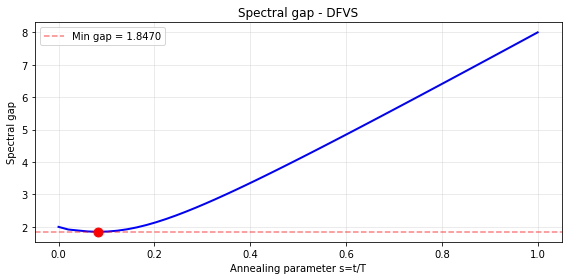

Solution (ground state |111111111>, first 5 bits):
Feedback vertex set: [0, 1, 2, 3, 4]
FVS size: 5


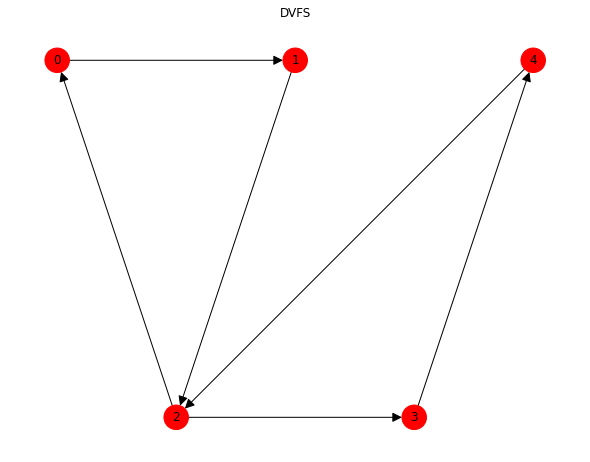

Remaining digraph is acyclic (DAG): True


In [20]:
DG = nx.DiGraph()
DG.add_edges_from([(0, 1), (1, 2), (2, 0), (2, 3), (3, 4), (4, 2)])
n = DG.number_of_nodes()
print(f"Graph: {n} nodes, {DG.number_of_edges()} edges")

sg = SpinGlass()
sg.fromGraph(DG, 'dfvs')
print(f"Directed FVS - Number of qubits: {sg.num_qubits} ({n} vertex variables + {sg.num_qubits - n} slack bits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='DFVS')

bs = res['ground_bitstring']
nodes = list(DG.nodes())
fvs = [nodes[i] for i in range(n) if bs[i] == '1']
print(f"Solution (ground state |{bs}>, first {n} bits):")
print(f"Feedback vertex set: {fvs}")
print(f"FVS size: {len(fvs)}")

plt.figure(figsize=(8, 6))
pos = {0: (0, 1), 1: (1, 1), 2: (0.5, 0), 3: (1.5, 0), 4: (2, 1)}
colors = ['red' if bs[i] == '1' else 'lightskyblue' for i in range(n)]
nx.draw(DG, pos, with_labels=True, node_color=colors, node_size=600, arrows=True, arrowsize=20)
plt.title("DVFS")
plt.show()

DH = DG.copy()
DH.remove_nodes_from(fvs)
is_dag = nx.is_directed_acyclic_graph(DH)
print(f"Remaining digraph is acyclic (DAG): {is_dag}")

### Feedback Edge Set

Find minimum set of edges whose removal makes the graph acyclic.

Hamiltonian: $H = B\sum_e x_e + A\sum_{\text{cycles } C}\left(\sum_{e\in C} x_e - 1 - y_C\right)^2$

In [ ]:
G = nx.complete_graph(4)
m = G.number_of_edges()
print(f"K4: {G.number_of_nodes()} nodes, {m} edges")

sg = SpinGlass()
sg.fromGraph(G, 'fes')
print(f"Feedback Edge Set - Number of qubits: {sg.num_qubits} ({m} edge variables + {sg.num_qubits - m} slack bits)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='FES')

bs = res['ground_bitstring']
edges = list(G.edges())
fes = [edges[i] for i in range(m) if bs[i] == '1']
remaining = [edges[i] for i in range(m) if bs[i] == '0']
print(f"Solution (ground state |{bs}>, first {m} bits):")
print(f"Feedback edges (to remove): {fes}")
print(f"FES size: {len(fes)}")
print(f"Remaining edges: {remaining}")

plt.figure(figsize=(6, 6))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='wheat', node_size=700, width=1, alpha=0.5)
nx.draw_networkx_edges(G, pos, edgelist=fes, edge_color='red', width=3, style='dashed')
nx.draw_networkx_edges(G, pos, edgelist=remaining, edge_color='green', width=2)
plt.title("FES, K4")
plt.show()

R = nx.Graph()
R.add_edges_from(remaining)
R.add_nodes_from(G.nodes())
is_acyclic = nx.is_forest(R)
print(f"Remaining graph is acyclic: {is_acyclic}")

K4: 4 nodes, 6 edges
Feedback Edge Set - Number of qubits: 12 (6 edge variables + 6 slack bits)


## 7. Graph Isomorphism

Determine if two graphs are structurally identical.

Hamiltonian: $H = A\sum_u \left(1 - \sum_v x_{u,v}\right)^2 + A\sum_v \left(1 - \sum_u x_{u,v}\right)^2 + A\sum_{(u,u')\in E_1, (v,v')\notin E_2} x_{u,v}x_{u',v'}$

In [ ]:
G1 = nx.cycle_graph(4)
G2 = nx.Graph()
G2.add_edges_from([(0, 1), (1, 2), (2, 3), (3, 0)])

print(f"G1: C4")
print(f"G2: Another 4-cycle with same structure")

sg = SpinGlass()
sg.fromGraph((G1, G2), 'isomorphism')

n = G1.number_of_nodes()
print(f"Number of qubits: {sg.num_qubits} ({n} x {n} permutation matrix)")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='Graph isomorphism')

bs = res['ground_bitstring']
print(f"Solution (ground state |{bs}>):")
print(f"Permutation matrix (x[u,v] = vertex u in G1 maps to vertex v in G2):")
for u in range(n):
    row = [bs[u * n + v] for v in range(n)]
    mapped_to = [v for v in range(n) if bs[u * n + v] == '1']
    print(f"G1 vertex {u}: {row}  -> G2 vertex {mapped_to}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
nx.draw(G1, ax=axes[0], with_labels=True, node_color='lightblue', node_size=700)
axes[0].set_title("G1=C4")
nx.draw(G2, ax=axes[1], with_labels=True, node_color='lightgreen', node_size=700)
axes[1].set_title("G2")
plt.suptitle("Graph isomorphism, C4")
plt.tight_layout()
plt.show()

mapping = {}
for u in range(n):
    mapped_to = [v for v in range(n) if bs[u * n + v] == '1']
    if len(mapped_to) == 1:
        mapping[u] = mapped_to[0]
is_bijection = (len(mapping) == n and len(set(mapping.values())) == n)
edges_preserved = is_bijection and all(G2.has_edge(mapping[u], mapping[v]) for u, v in G1.edges())
print(f"Valid bijection: {is_bijection}")
print(f"Edges preserved: {edges_preserved}")
print(f"Valid isomorphism: {is_bijection and edges_preserved}")

## Binary Integer Linear Programming

General BILP problems of the form:
- Minimize: $c^T x$
- Subject to: $Ax = b$, $x \in \{0,1\}^n$

Hamiltonian: $H = B\sum_i c_i x_i + A\sum_j \left(\sum_i A_{ji} x_i - b_j\right)^2$

In [ ]:
c = [3, 2, 5, 4]
A_eq = [[1, 1, 0, 0], [0, 0, 1, 1]]
b_eq = [1, 1]

print("BILP Instance:")
print(f"Minimize: 3*x0 + 2*x1 + 5*x2 + 4*x3")
print(f"Subject to: x0 + x1 = 1, x2 + x3 = 1, x_i in {{0, 1}}")

sg = SpinGlass()
sg.fromBILP(c, A_eq=A_eq, b_eq=b_eq)
print(f"Number of qubits: {sg.num_qubits}")

sim = Simulation()
sim.initialize(sg, num_steps=50)
sim.execute()
results = sim.results()

res = display_results(sg, results, title='BILP')

bs = res['ground_bitstring']
n = len(c)
assignment = {f'x{i}': int(bs[i]) for i in range(n)}
obj_value = sum(c[i] * int(bs[i]) for i in range(n))
print(f"Solution (ground state |{bs}>):")
print(f"Variables: {assignment}")
print(f"Objective value: {obj_value}")
for j, (row, rhs) in enumerate(zip(A_eq, b_eq)):
    lhs = sum(row[i] * int(bs[i]) for i in range(n))
    terms = ' + '.join(f'{row[i]}*x{i}' for i in range(n) if row[i] != 0)
    print(f"Constraint {j+1}: {terms} = {lhs} (should be {rhs})")